In [39]:
%run notebook_setup.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils.config import load_config
sns.set_theme(
    context="paper", 
    style="darkgrid",
    palette="muted")

In [2]:
config = load_config()

In [3]:
raw_data = config["paths"]["raw_data"]
raw_data

'/home/inventor/Crop_yield_prediction/data/raw/crop_yield.csv'

In [4]:
df = pd.read_csv(raw_data)

In [5]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [6]:
df.shape

(19689, 10)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  str    
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  str    
 3   State            19689 non-null  str    
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), str(3)
memory usage: 1.5 MB


In [8]:
df.describe()

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
count,19689.000000,1.968900e+04,1.968900e+04,19689.000000,1.968900e+04,1.968900e+04,19689.000000
mean,2009.127584,1.799266e+05,1.643594e+07,1437.755177,2.410331e+07,4.884835e+04,79.954009
std,6.498099,7.328287e+05,2.630568e+08,816.909589,9.494600e+07,2.132874e+05,878.306193
min,1997.000000,5.000000e-01,0.000000e+00,301.300000,5.417000e+01,9.000000e-02,0.000000
25%,2004.000000,1.390000e+03,1.393000e+03,940.700000,1.880146e+05,3.567000e+02,0.600000
50%,2010.000000,9.317000e+03,1.380400e+04,1247.600000,1.234957e+06,2.421900e+03,1.030000
75%,2015.000000,7.511200e+04,1.227180e+05,1643.700000,1.000385e+07,2.004170e+04,2.388889
max,2020.000000,5.080810e+07,6.326000e+09,6552.700000,4.835407e+09,1.575051e+07,21105.000000


In [9]:
df.isnull().sum()

Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
# Value Counts of Crops
df["Crop"].value_counts()

Crop
Rice                     1197
Maize                     975
Moong(Green Gram)         740
Urad                      733
Groundnut                 725
Sesamum                   685
Potato                    628
Sugarcane                 605
Wheat                     545
Rapeseed &Mustard         528
Bajra                     524
Jowar                     513
Arhar/Tur                 508
Ragi                      498
Gram                      490
Small millets             485
Cotton(lint)              476
Onion                     454
Sunflower                 441
Dry chillies              419
Other Kharif pulses       382
Horse-gram                371
Peas & beans (Pulses)     369
Tobacco                   364
Other  Rabi pulses        355
Soyabean                  349
Turmeric                  337
Masoor                    324
Ginger                    323
Linseed                   308
Castor seed               300
Barley                    297
Sweet potato              273
Garli

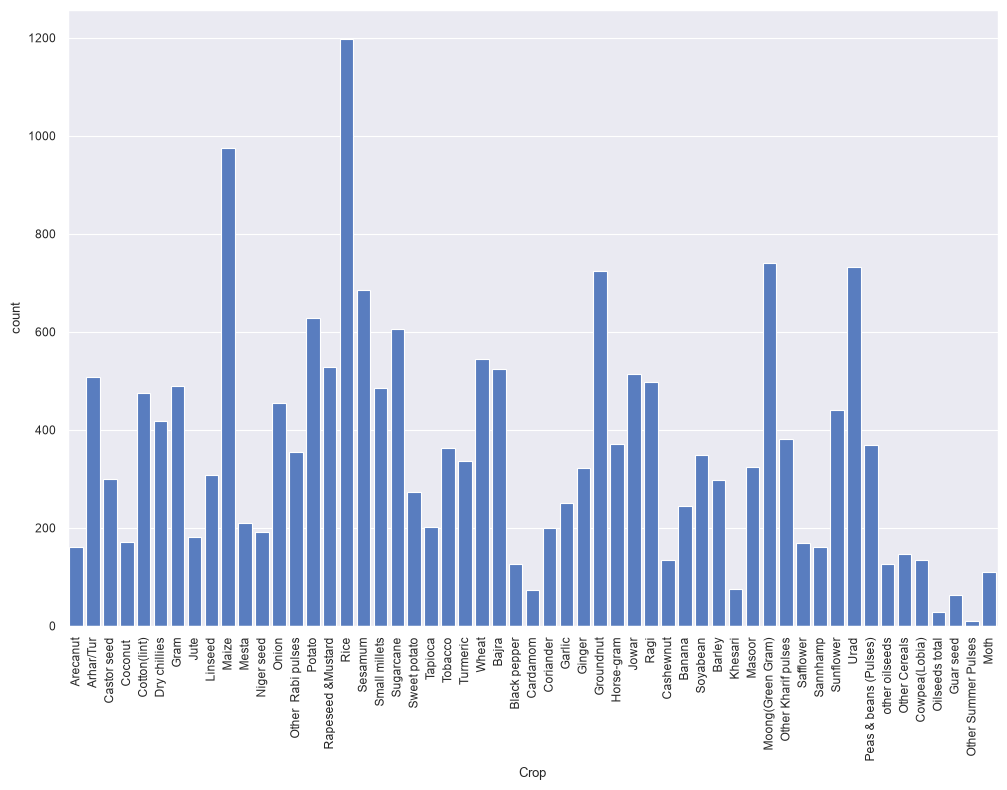

In [40]:
plt.figure(figsize=(12, 8))
sns.countplot(data=df, x=df["Crop"])
plt.xticks(rotation=90)
plt.show()

In [41]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


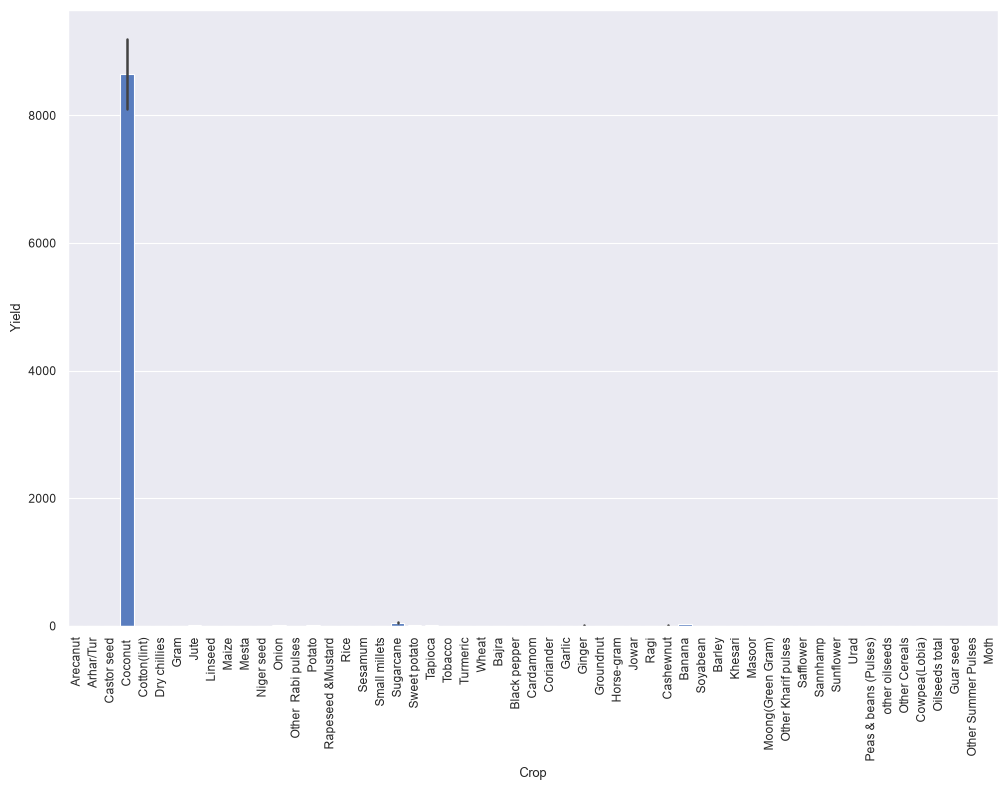

In [42]:
# Distribution of Crop vs yield
plt.figure(figsize=(12, 8))
sns.barplot(data=df, x="Crop", y="Yield")
plt.xticks(rotation=90)
plt.show()

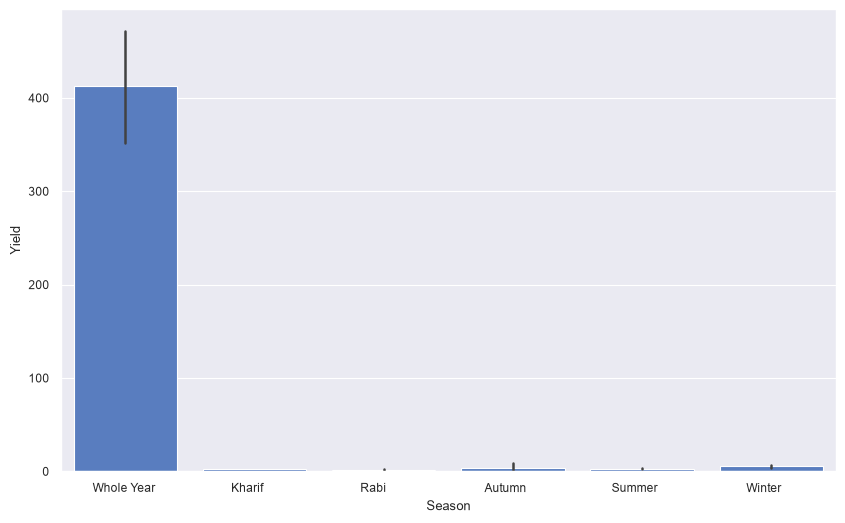

In [43]:
# Yield vs Season
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="Season", y="Yield")
plt.show()

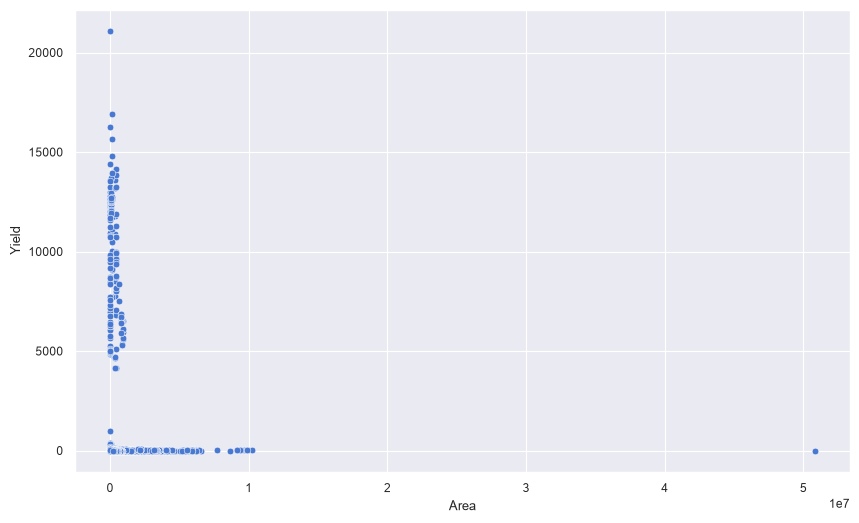

In [45]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Area", y="Yield")
plt.show()

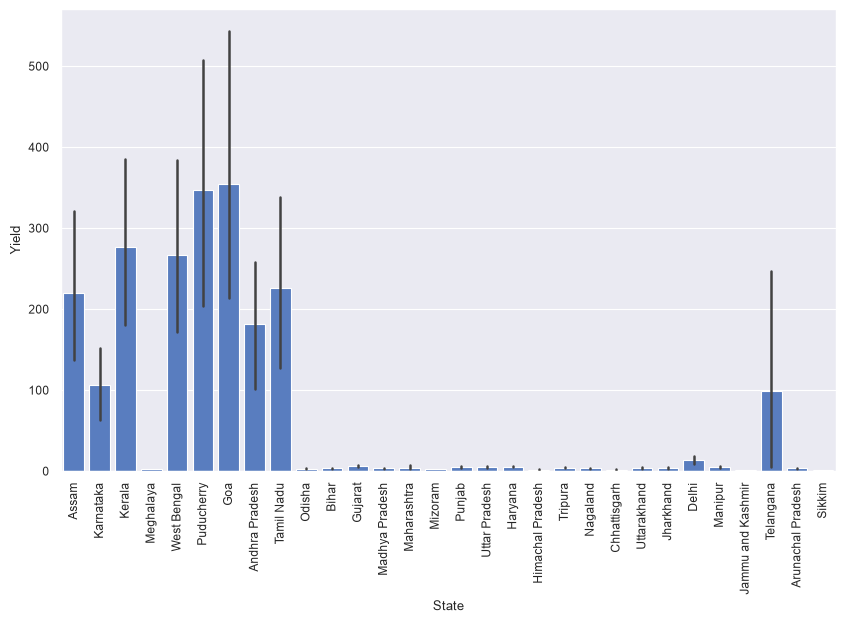

In [48]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="State", y="Yield")
plt.xticks(rotation=90)
plt.show()

<Figure size 1200x800 with 0 Axes>

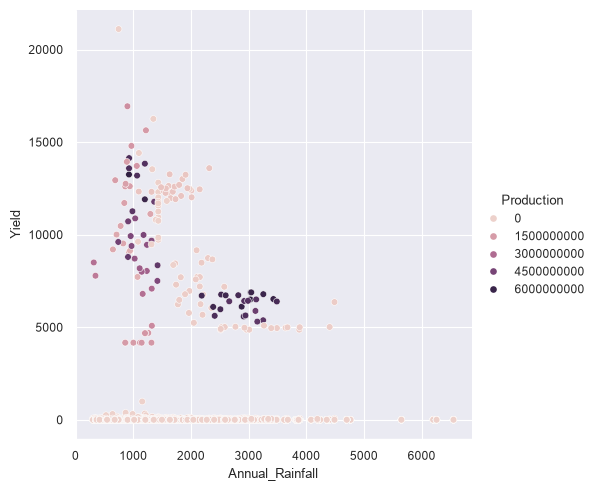

In [57]:
plt.figure(figsize=(12, 8))
sns.relplot(data=df, x="Annual_Rainfall", y="Yield", hue="Production")
plt.show()

<Figure size 1000x600 with 0 Axes>

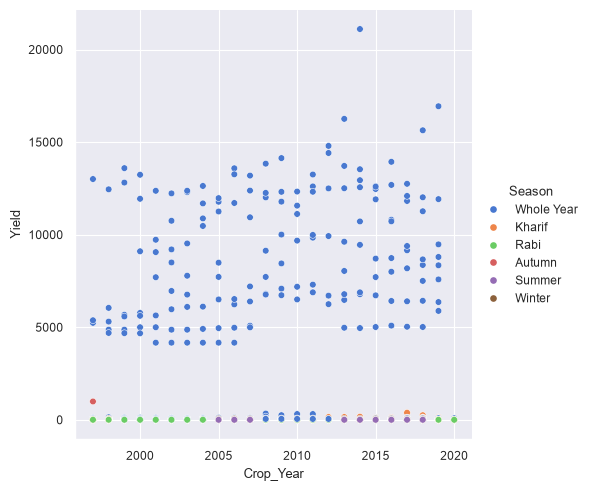

In [66]:
plt.figure(figsize=(10, 6))
sns.relplot(data=df, x="Crop_Year", y="Yield", hue="Season")
plt.show()

In [65]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


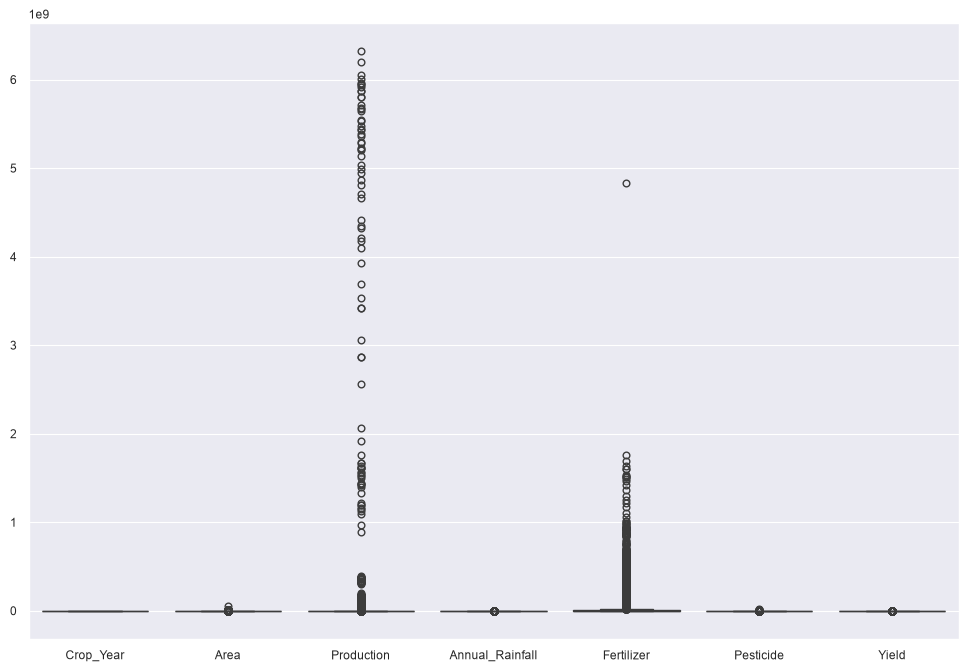

In [67]:
plt.figure(figsize=(12, 8))
sns.boxplot(df)
plt.show()

### Outliers 
 Outliers are in all numerical features except Crop_Year

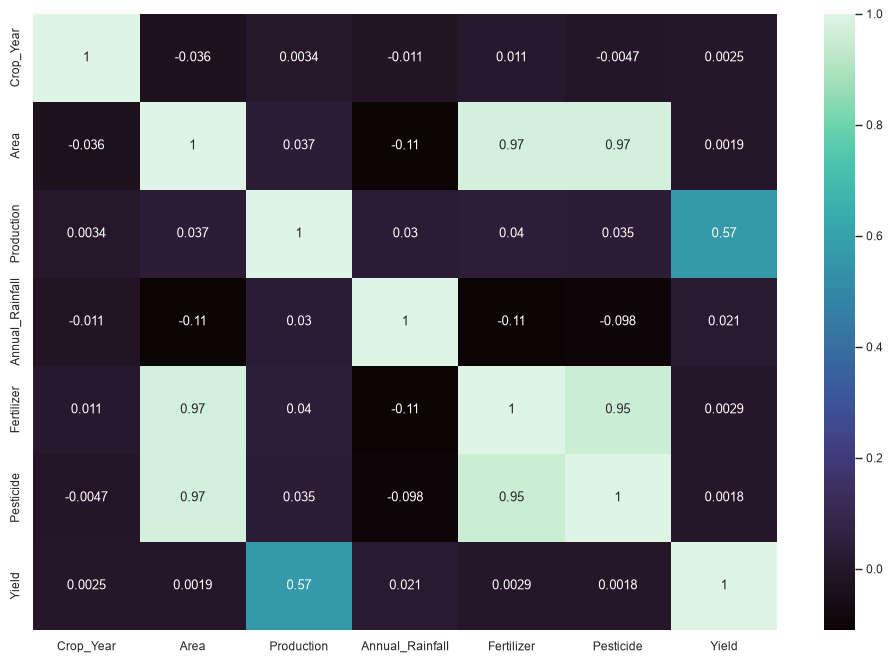

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
Crop_Year,1.000000,-0.035686,0.003366,-0.011187,0.011169,-0.004657,0.002539
Area,-0.035686,1.000000,0.037441,-0.106054,0.973255,0.973479,0.001858
Production,0.003366,0.037441,1.000000,0.029879,0.039799,0.035171,0.570809
Annual_Rainfall,-0.011187,-0.106054,0.029879,1.000000,-0.109734,-0.097657,0.020761
Fertilizer,0.011169,0.973255,0.039799,-0.109734,1.000000,0.954991,0.002862
Pesticide,-0.004657,0.973479,0.035171,-0.097657,0.954991,1.000000,0.001782
Yield,0.002539,0.001858,0.570809,0.020761,0.002862,0.001782,1.000000


In [75]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="mako")
plt.show()

corr

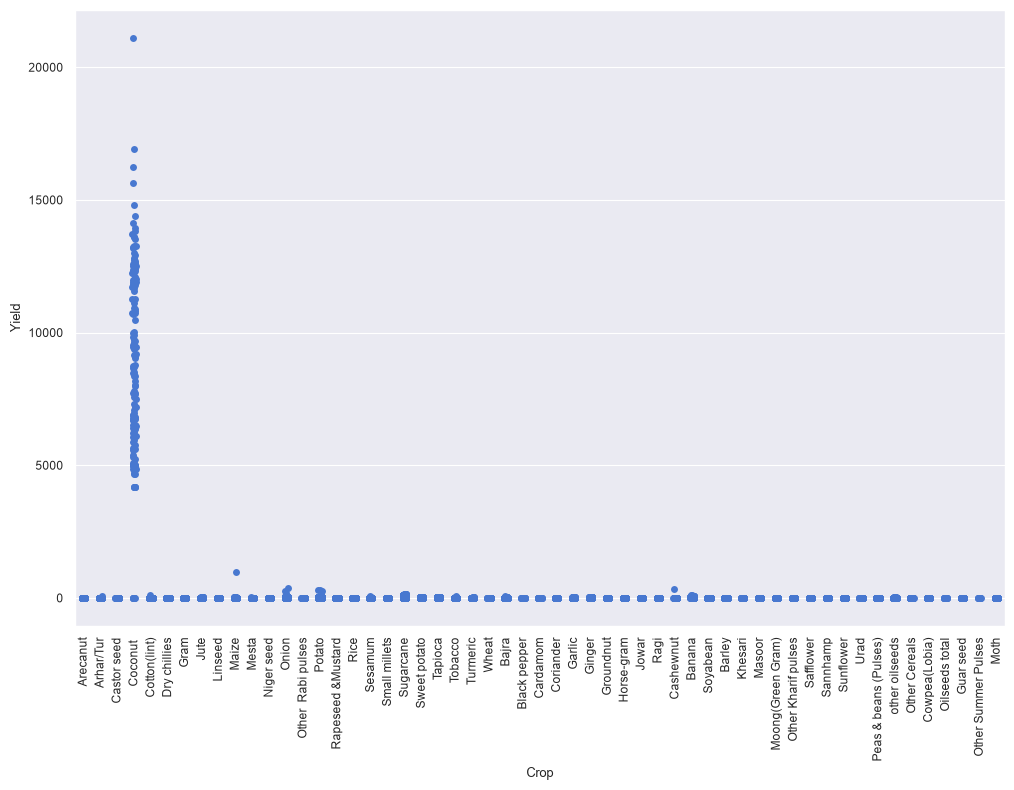

In [78]:
plt.figure(figsize=(12,8))
sns.stripplot(data=df, x="Crop", y="Yield")
plt.xticks(rotation=90)
plt.show()

In [84]:
from scipy.stats import chi2_contingency

def cramer_v(x, y):
    confusion = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion)[0]
    n = confusion.sum().sum()
    phi2 = chi2 / n
    r, k = confusion.shape
    return np.sqrt(phi2 / min(k-1, r-1))



In [85]:
print(f"Cremera Value for Crop feature: {cramer_v(df["Crop"], df["Yield"])}")

Cremera Value for Crop feature: 0.832315824705197


In [91]:
cat_features = df.select_dtypes(exclude=["number"]).columns.tolist()

for feature in cat_features:
    print(f"Cramera Value of {feature}: {cramer_v(df[feature], df["Yield"])}")

Cramera Value of Crop: 0.832315824705197
Cramera Value of Season: 0.8728919403413522
Cramera Value of State: 0.8288807039497869


In [99]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import LabelEncoder

In [102]:
def mutual_information(df, target="Yield"):
    X = df.drop(columns=["Yield"]).copy()
    y = df["Yield"]

    for feature in cat_features:
        X[feature] = LabelEncoder().fit_transform(X[feature]).astype(str)
    
    mutual_score = mutual_info_regression(X, y, random_state=42)

    ml_df = pd.DataFrame({
        "Features": X.columns,
        "mutual_score": mutual_score
    }).sort_values(by="mutual_score", ascending=False)

    return ml_df

In [106]:
mutual_score = mutual_information(df)

In [107]:
mutual_score

,Features,mutual_score
0,Crop,0.906335
5,Production,0.460155
3,State,0.377045
4,Area,0.254573
6,Annual_Rainfall,0.216861
7,Fertilizer,0.159913
2,Season,0.148879
8,Pesticide,0.136107
1,Crop_Year,0.003854


<Axes: xlabel='Features', ylabel='mutual_score'>

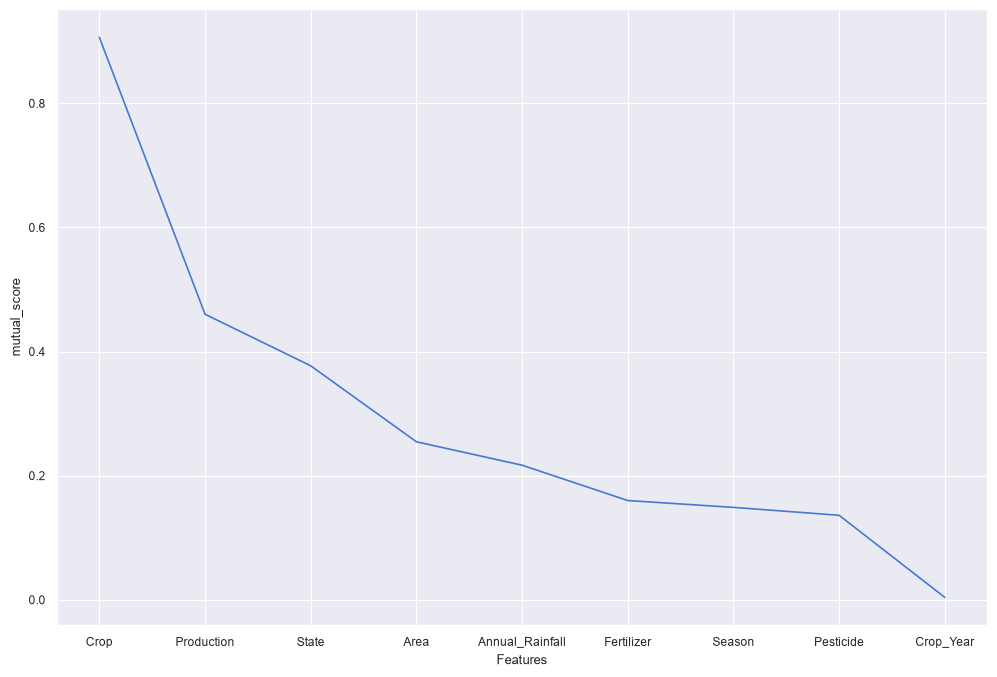

In [108]:
plt.figure(figsize=(12, 8))
sns.lineplot(data=mutual_score, x="Features", y="mutual_score")

## Summary 
 - No missing values and duplicated values.
 - have outliers in all numerical values except Crop_Year
 - have no unnecassary features to drop
 - Need to Encode the 'Crop, State, Season'